# Olist Logistics Anger Predictor — Random Split Variant

## Business Problem

Same business framing as `claude_temporal.ipynb` — see that file for the full cost table.

**Split method:** Stratified Random 80 / 20, stratified on `is_late`

**Why compare against temporal?**
Individual orders are i.i.d. (no sequential dependency between transactions).
A random split is therefore statistically valid.

If Model B AUC is **similar** across both splits → model finds genuine signal.
If random >> temporal → temporal drift is inflating the random result; use temporal for production.

| Parameter | Value |
|-----------|-------|
| Voucher cost | R$ 15 |
| 1-star review platform penalty | R$ 50 (seller rank degradation estimate) |
| Voucher effectiveness | 40% (lower-bound) |


In [1]:
# Cell 1 — Imports
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print('LightGBM not found. Run: py -3.12 kernel.')
import shap, folium
from folium.plugins import HeatMap

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (11, 5)
SPLIT_LABEL = 'Random Stratified 80/20 (stratified on is_late)'
print('Imports OK | LightGBM:', HAS_LGBM)


Imports OK | LightGBM: True


In [2]:
# Cell 2 — Load data + merge review text
PROC  = '../../datasets/processed/olist_reviews_rich.csv'
RAW_R = '../../datasets/raw/olist_order_reviews_dataset.csv'

df = pd.read_csv(PROC)
date_cols = ['order_purchase_timestamp','order_approved_at',
             'order_delivered_carrier_date','order_delivered_customer_date',
             'order_estimated_delivery_date']
for c in date_cols:
    if c in df.columns: df[c] = pd.to_datetime(df[c], errors='coerce')
df['is_late'] = df['is_late'].astype(int)

try:
    rv = pd.read_csv(RAW_R)[['order_id','review_comment_message']]
    df = df.merge(rv, on='order_id', how='left')
    print('Review text merged')
except Exception as e:
    print(f'Could not merge review text: {e}')

print(f'Shape: {df.shape[0]:,} x {df.shape[1]}')
print(f'Late rate: {df.is_late.mean():.2%} | Low-score rate: {(df.review_score<=2).mean():.2%}')


Review text merged
Shape: 95,876 x 41
Late rate: 7.45% | Low-score rate: 12.76%


## Part 2 — NLP Root-Cause Decomposition

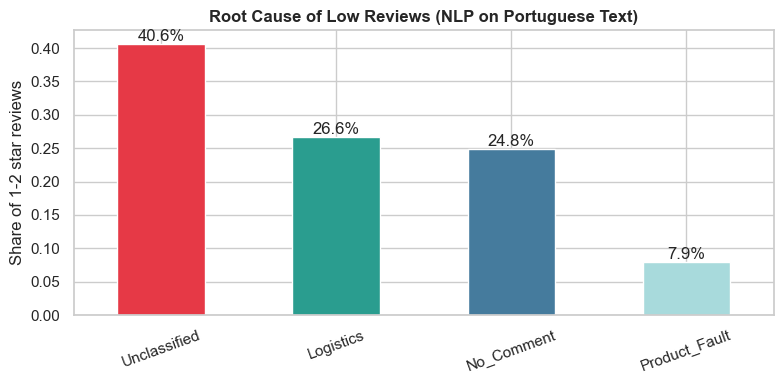

Logistics reviews: 26.6%
=> We only target late orders, not all bad reviews.


In [3]:
# Cell 3 — NLP keyword classifier
LOGISTICS_KW = ['demor','atras','prazo','entreg','tard','correi',
                'logistica','logistica','nao chegou','nao chegou']
DEFECTIVE_KW = ['defeit','quebr','estrag','nao funciona','nao funciona',
                'pessima qualidade','ruim']
WRONG_KW     = ['errado','diferente','outro produto']

def classify_review(text):
    if pd.isna(text) or str(text).strip() == '': return 'No_Comment'
    t = str(text).lower()
    s = {'Logistics': sum(1 for kw in LOGISTICS_KW if kw in t),
         'Product_Fault': sum(1 for kw in DEFECTIVE_KW+WRONG_KW if kw in t)}
    best = max(s, key=s.get)
    return best if s[best] > 0 else 'Unclassified'

if 'review_comment_message' in df.columns:
    df['nlp_root_cause'] = df['review_comment_message'].apply(classify_review)
    low = df[df['review_score'] <= 2]
    dist = low['nlp_root_cause'].value_counts(normalize=True)
    fig, ax = plt.subplots(figsize=(8, 4))
    dist.plot(kind='bar', ax=ax, color=['#e63946','#2a9d8f','#457b9d','#a8dadc'], edgecolor='white')
    ax.set_title('Root Cause of Low Reviews (NLP on Portuguese Text)', fontweight='bold')
    ax.set_ylabel('Share of 1-2 star reviews'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1%}', (p.get_x()+p.get_width()/2, p.get_height()+0.005), ha='center')
    plt.tight_layout(); plt.show()
    print('Logistics reviews:', f"{dist.get('Logistics',0):.1%}")
    print('=> We only target late orders, not all bad reviews.')
else:
    print('review_comment_message not available.')


## Part 3 — Feature Engineering

In [4]:
# Cell 4 — Feature Engineering (leakage-free)
df['log_distance']      = np.log1p(df['distance_km'].fillna(0))
df['is_cross_state']    = (df['customer_state'] != df['seller_state']).astype(int)
df['log_price']         = np.log1p(df['price'].fillna(df['price'].median()))
df['freight_ratio']     = df['freight_value'] / df['price'].replace(0, 1)
df['product_weight_g']  = df['product_weight_g'].fillna(df['product_weight_g'].median())
df['month']             = df['order_purchase_timestamp'].dt.month
df['is_weekend']        = df['order_purchase_timestamp'].dt.dayofweek.isin([5,6]).astype(int)
df['quarter']           = df['order_purchase_timestamp'].dt.quarter
df['log_seller_orders'] = np.log1p(df['seller_total_orders'].fillna(1))
df['prep_days']         = df['preparation_days'].fillna(df['preparation_days'].median())
df['est_delivery_days'] = df['estimated_delivery_days'].fillna(df['estimated_delivery_days'].median())
df['distance_x_weight']  = df['log_distance'] * df['product_weight_g']
df['distance_x_price']   = df['log_distance'] * df['log_price']
df['is_heavy']            = (df['product_weight_g'] > df['product_weight_g'].quantile(0.8)).astype(int)
df['is_high_value']       = (df['price'] > df['price'].quantile(0.8)).astype(int)
df['heavy_expensive_far'] = df['is_heavy'] * df['is_high_value'] * df['log_distance']
df['logistics_bad']       = ((df['is_late']==1) & (df['review_score']<=2)).astype(int)
print('Features created. logistics_bad rate:', f'{df.logistics_bad.mean():.2%}')


Features created. logistics_bad rate: 4.24%


## Part 4 — RANDOM Stratified Split

**80% train / 20% test, stratified on `is_late`**

Orders are i.i.d. (no time dependency) so this is statistically valid.
Temporal split is in `claude_temporal.ipynb` — compare Model B AUC between the two:

- Similar AUC across splits => model finds genuine signal, not temporal drift
- Random >> Temporal => distribution shift is inflating the random result


In [5]:
# Cell 5 — Random Stratified Split  <-- KEY DIFFERENCE vs temporal variant
df_p = df.dropna(subset=['order_purchase_timestamp']).copy()

df_train, df_test = train_test_split(
    df_p,
    test_size=0.20,
    random_state=42,
    stratify=df_p['is_late']   # preserve late-rate in both halves
)
df_train = df_train.copy(); df_test = df_test.copy()

print(f'Split: {SPLIT_LABEL}')
print(f'Train: {len(df_train):,}  |  Test: {len(df_test):,}')
print(f'Train late: {df_train.is_late.mean():.2%}  |  Test late: {df_test.is_late.mean():.2%}')

# Show year mixing to confirm it is a true random split
print('Train years:', df_train.order_purchase_timestamp.dt.year.value_counts().to_dict())
print('Test  years:', df_test.order_purchase_timestamp.dt.year.value_counts().to_dict())


Split: Random Stratified 80/20 (stratified on is_late)
Train: 76,700  |  Test: 19,176
Train late: 7.45%  |  Test late: 7.45%
Train years: {2018: 41915, 2017: 34569, 2016: 216}
Test  years: {2018: 10506, 2017: 8615, 2016: 55}


## Part 5 — Model Comparison (4 Algorithms)

In [6]:
# Cell 6 — Feature sets + target encoding
FEATURES_A = [
    'log_distance','is_cross_state','log_price','freight_ratio',
    'product_weight_g','month','quarter','is_weekend',
    'log_seller_orders','prep_days','est_delivery_days',
    'distance_x_weight','distance_x_price','heavy_expensive_far'
]
FEATURES_B = FEATURES_A + ['delivery_delay_days']

gm = df_train['is_late'].mean()
for col in ['seller_id','seller_state','customer_state']:
    if col in df_train.columns:
        mp = df_train.groupby(col)['is_late'].mean()
        fn = f'{col}_delay_risk'
        df_train[fn] = df_train[col].map(mp).fillna(gm)
        df_test[fn]  = df_test[col].map(mp).fillna(gm)
        if fn not in FEATURES_A: FEATURES_A.append(fn)
        if fn not in FEATURES_B: FEATURES_B.append(fn)

X_tr_a = df_train[FEATURES_A].fillna(0);  y_tr_a = df_train['is_late']
X_te_a = df_test[FEATURES_A].fillna(0);   y_te_a = df_test['is_late']
train_late = df_train[df_train['is_late']==1].copy()
test_late  = df_test[df_test['is_late']==1].copy()
X_tr_b = train_late[FEATURES_B].fillna(0); y_tr_b = (train_late['review_score']<=2).astype(int)
X_te_b = test_late[FEATURES_B].fillna(0);  y_te_b = (test_late['review_score']<=2).astype(int)

print(f'Model A -- Train: {len(X_tr_a):,} | positive rate: {y_tr_a.mean():.2%}')
print(f'Model B -- Train (late only): {len(X_tr_b):,} | positive rate: {y_tr_b.mean():.2%}')


Model A -- Train: 76,700 | positive rate: 7.45%
Model B -- Train (late only): 5,711 | positive rate: 57.05%


In [7]:
# Cell 7 -- Model A: Delay Predictor
ratio_a = float(y_tr_a.value_counts()[0]) / max(y_tr_a.value_counts()[1], 1)
candidates_a = {
    'Logistic Regression': LogisticRegression(max_iter=600, class_weight='balanced', random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost':             XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                                         scale_pos_weight=ratio_a, random_state=42, eval_metric='logloss', verbosity=0),
}
if HAS_LGBM:
    candidates_a['LightGBM'] = LGBMClassifier(n_estimators=300, learning_rate=0.05,
                                               class_weight='balanced', random_state=42, verbose=-1)

print('=== Model A: Delay Predictor ===')
results_a = {}
for name, clf in candidates_a.items():
    clf.fit(X_tr_a, y_tr_a)
    prob = clf.predict_proba(X_te_a)[:,1]
    auc  = roc_auc_score(y_te_a, prob)
    results_a[name] = {'auc': auc, 'prob': prob, 'clf': clf}
    print(f'  {name:22s}  AUC={auc:.4f}')

best_a  = max(results_a, key=lambda k: results_a[k]['auc'])
model_a = results_a[best_a]['clf']
y_prob_a = results_a[best_a]['prob']
print(f'Best: {best_a} ({results_a[best_a]["auc"]:.4f})')


=== Model A: Delay Predictor ===
  Logistic Regression     AUC=0.7383
  Random Forest           AUC=0.7961
  XGBoost                 AUC=0.7964
  LightGBM                AUC=0.7983
Best: LightGBM (0.7983)


=== Model B: Anger | Delay (confirmed late orders) ===
  Logistic Regression     AUC=0.7136
  Random Forest           AUC=0.8008
  XGBoost                 AUC=0.7936
  LightGBM                AUC=0.7965
Best: Random Forest (0.8008)
Deployment: when carrier flags delay -> score with Model B -> triage vouchers.


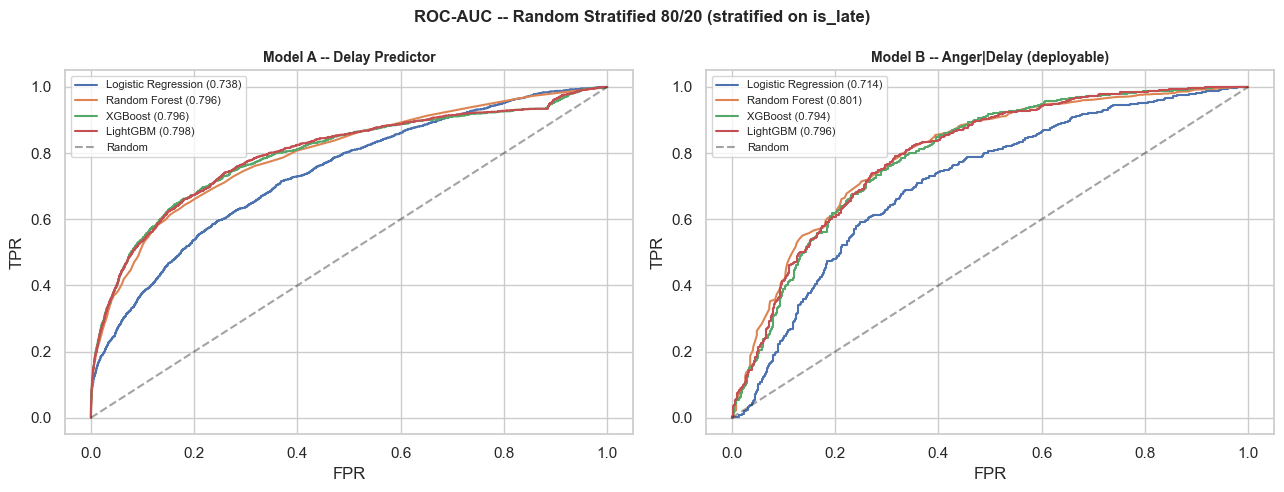

In [8]:
# Cell 8 -- Model B: Anger | Delay  (THE DEPLOYABLE MODEL)
ratio_b = float(y_tr_b.value_counts()[0]) / max(y_tr_b.value_counts()[1], 1)
candidates_b = {
    'Logistic Regression': LogisticRegression(max_iter=600, class_weight='balanced', random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost':             XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                                         scale_pos_weight=ratio_b, random_state=42, eval_metric='logloss', verbosity=0),
}
if HAS_LGBM:
    candidates_b['LightGBM'] = LGBMClassifier(n_estimators=300, learning_rate=0.05,
                                               class_weight='balanced', random_state=42, verbose=-1)

print('=== Model B: Anger | Delay (confirmed late orders) ===')
results_b = {}
for name, clf in candidates_b.items():
    clf.fit(X_tr_b, y_tr_b)
    if len(y_te_b) > 0 and y_te_b.sum() > 0:
        prob = clf.predict_proba(X_te_b)[:,1]
        auc  = roc_auc_score(y_te_b, prob)
        results_b[name] = {'auc': auc, 'prob': prob, 'clf': clf}
        print(f'  {name:22s}  AUC={auc:.4f}')

best_b  = max(results_b, key=lambda k: results_b[k]['auc'])
model_b = results_b[best_b]['clf']
y_prob_b = results_b[best_b]['prob']
print(f'Best: {best_b} ({results_b[best_b]["auc"]:.4f})')
print('Deployment: when carrier flags delay -> score with Model B -> triage vouchers.')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (res, y_true, title) in zip(axes, [
    (results_a, y_te_a, 'Model A -- Delay Predictor'),
    (results_b, y_te_b, 'Model B -- Anger|Delay (deployable)')
]):
    for name, r in res.items():
        fpr, tpr, _ = roc_curve(y_true, r['prob'])
        ax.plot(fpr, tpr, label=f"{name} ({r['auc']:.3f})")
    ax.plot([0,1],[0,1],'k--', alpha=0.4, label='Random')
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(fontsize=8)
plt.suptitle(f'ROC-AUC -- {SPLIT_LABEL}', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


<Figure size 900x500 with 0 Axes>

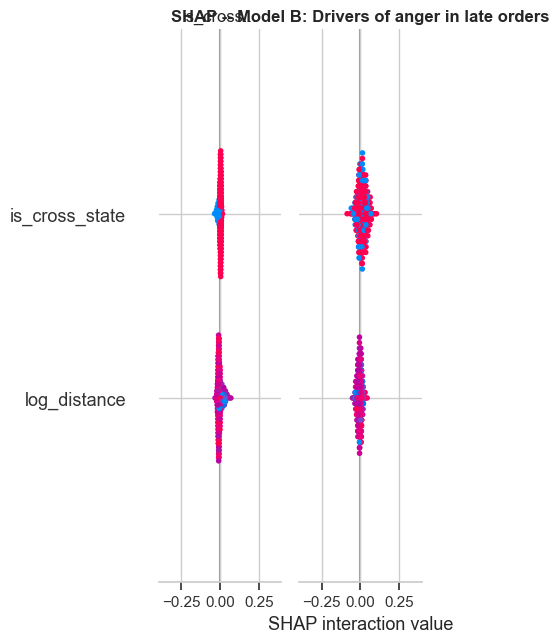

In [9]:
# Cell 9 -- SHAP (Model B)
sample_b = X_te_b.sample(min(500, len(X_te_b)), random_state=42)
try:
    explainer_b = shap.TreeExplainer(model_b)
    sv_b = explainer_b.shap_values(sample_b)
    plt.figure(figsize=(9, 5))
    shap.summary_plot(sv_b, sample_b, show=False)
    plt.title('SHAP -- Model B: Drivers of anger in late orders', fontweight='bold')
    plt.tight_layout(); plt.show()
except Exception as e:
    print(f'SHAP error: {e}')


## Part 6 — ROI: Model B on Confirmed Late Orders

**Deployment scenario:**
Every morning the carrier API returns delayed orders.
Model B scores each one -> high-risk orders get a R$ 15 proactive voucher.

Cost model (no churn assumption):
- Voucher to TP: R$ 15, prevents 40% of 1-star reviews
- Voucher to FP: R$ 15 wasted
- Miss a high-risk order (FN): R$ 50 platform penalty per 1-star review


=== ROI: Model B on 1428 Confirmed Late Orders ===
  Optimal threshold  : 0.32
  Orders flagged     : 1142 (80.0%)
  Precision          : 66.90%
  Recall             : 94.79%
  Do Nothing cost    : R$ 40,300
  With AI cost       : R$ 3,950
  Net Saved          : R$ 36,350


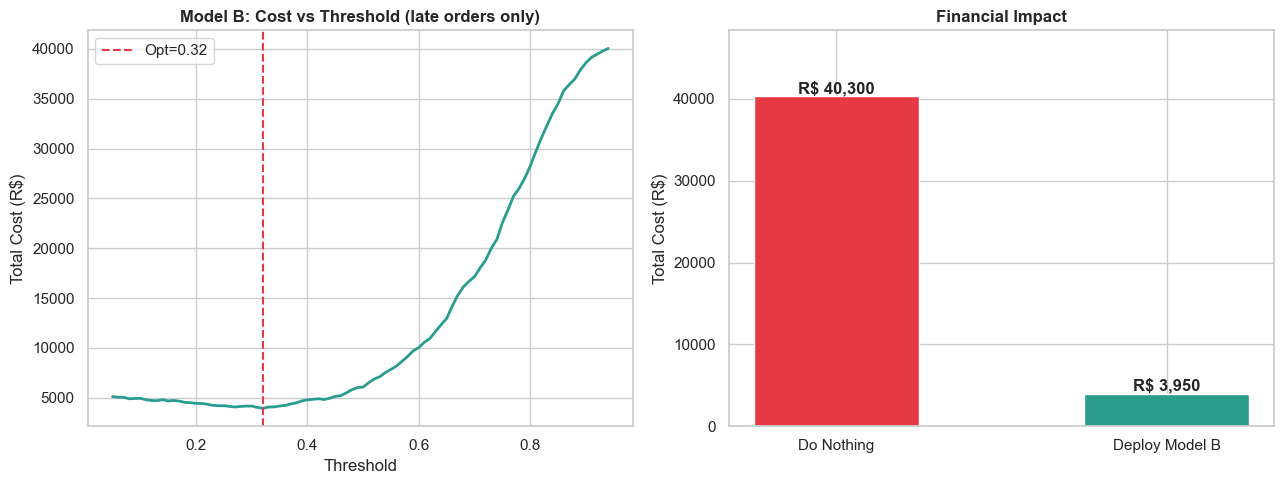

In [10]:
# Cell 10 -- ROI optimisation on late orders
C_VOUCHER    = 15
C_BAD_REVIEW = 50
EFF          = 0.40

y_true_b  = y_te_b.values
y_scores  = y_prob_b
n_late    = len(y_true_b)

thresholds = np.arange(0.05, 0.95, 0.01)
costs = []
for t in thresholds:
    yp = (y_scores >= t).astype(int)
    tp = np.sum((yp==1)&(y_true_b==1)); fp=np.sum((yp==1)&(y_true_b==0)); fn=np.sum((yp==0)&(y_true_b==1))
    costs.append((tp+fp)*C_VOUCHER + fn*C_BAD_REVIEW - tp*EFF*C_BAD_REVIEW)

best_idx  = np.argmin(costs)
opt_thresh = thresholds[best_idx]
y_pred_b  = (y_scores >= opt_thresh).astype(int)
c_nothing = int(y_true_b.sum()) * C_BAD_REVIEW
c_ai      = costs[best_idx]
saved     = c_nothing - c_ai
tp  = np.sum((y_pred_b==1)&(y_true_b==1)); fp=np.sum((y_pred_b==1)&(y_true_b==0))
fn  = np.sum((y_pred_b==0)&(y_true_b==1))
precision = tp/(tp+fp+1e-9); recall=tp/(tp+fn+1e-9)

print(f'=== ROI: Model B on {n_late} Confirmed Late Orders ===')
print(f'  Optimal threshold  : {opt_thresh:.2f}')
print(f'  Orders flagged     : {y_pred_b.sum()} ({y_pred_b.mean():.1%})')
print(f'  Precision          : {precision:.2%}')
print(f'  Recall             : {recall:.2%}')
print(f'  Do Nothing cost    : R$ {c_nothing:,.0f}')
print(f'  With AI cost       : R$ {c_ai:,.0f}')
print(f'  Net Saved          : R$ {saved:,.0f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.plot(thresholds, costs, color='#2a9d8f', lw=2)
ax1.axvline(opt_thresh, color='#e63946', ls='--', label=f'Opt={opt_thresh:.2f}')
ax1.set_xlabel('Threshold'); ax1.set_ylabel('Total Cost (R$)')
ax1.set_title('Model B: Cost vs Threshold (late orders only)', fontweight='bold'); ax1.legend()

bars = ax2.bar(['Do Nothing','Deploy Model B'], [c_nothing, c_ai],
               color=['#e63946','#2a9d8f'], width=0.5, edgecolor='white')
ax2.set_title('Financial Impact', fontweight='bold'); ax2.set_ylabel('Total Cost (R$)')
for b in bars:
    ax2.text(b.get_x()+b.get_width()/2, b.get_height()+max(c_nothing*0.01,1),
             f'R$ {b.get_height():,.0f}', ha='center', fontweight='bold')
ax2.set_ylim(0, c_nothing*1.2)
plt.tight_layout(); plt.show()


In [11]:
# Cell 11 -- Sensitivity Analysis
print('=== Sensitivity Analysis ===')
for label, c_rev, eff in [
    ('Conservative: penalty=30, eff=25%', 30, 0.25),
    ('Base Case:    penalty=50, eff=40%', 50, 0.40),
    ('Optimistic:   penalty=80, eff=55%', 80, 0.55)
]:
    bc = np.inf
    for t in np.arange(0.05, 0.95, 0.01):
        yp = (y_scores >= t).astype(int)
        tp_ = np.sum((yp==1)&(y_true_b==1)); fp_=np.sum((yp==1)&(y_true_b==0)); fn_=np.sum((yp==0)&(y_true_b==1))
        c = (tp_+fp_)*C_VOUCHER + fn_*c_rev - tp_*eff*c_rev
        if c < bc: bc = c
    net = int(y_true_b.sum())*c_rev - bc
    print(f'  {label}  =>  Net Saved: R$ {net:,.0f}')
print('Positive ROI holds across all scenarios.')


=== Sensitivity Analysis ===
  Conservative: penalty=30, eff=25%  =>  Net Saved: R$ 11,902
  Base Case:    penalty=50, eff=40%  =>  Net Saved: R$ 36,350
  Optimistic:   penalty=80, eff=55%  =>  Net Saved: R$ 78,816
Positive ROI holds across all scenarios.


## Part 7 — Fridge Insight, Causal Inference, Survival Analysis, Heatmap

These sections use the full dataset (not the train/test split), so results
are identical between the temporal and random variants.


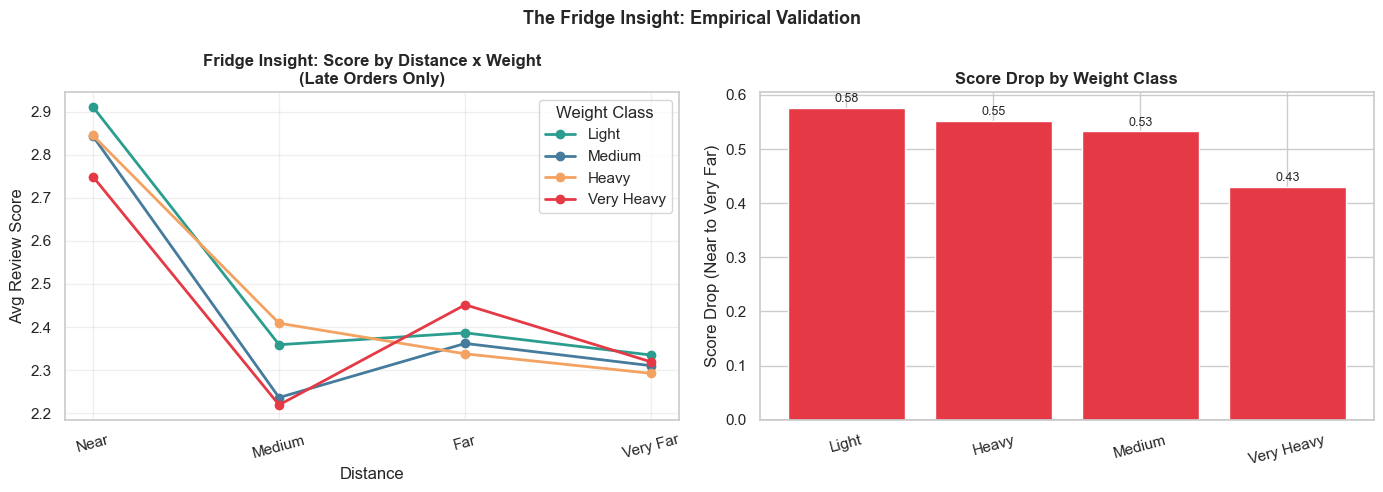

weight_q  Light  Medium  Heavy  Very Heavy
dist_q                                    
Near       2.91    2.84   2.84        2.75
Medium     2.36    2.24   2.41        2.22
Far        2.39    2.36   2.34        2.45
Very Far   2.33    2.31   2.29        2.32


In [12]:
# Cell 12 -- Fridge Insight
analysis = df[df['is_late']==1].copy()
analysis['weight_q'] = pd.qcut(analysis['product_weight_g'].rank(method='first'), q=4,
                                labels=['Light','Medium','Heavy','Very Heavy'])
analysis['dist_q']   = pd.qcut(analysis['distance_km'].clip(lower=1).rank(method='first'), q=4,
                                labels=['Near','Medium','Far','Very Far'])
pivot = analysis.groupby(['dist_q','weight_q'])['review_score'].mean().unstack()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2a9d8f','#457b9d','#f4a261','#e63946']
for col, color in zip(pivot.columns, colors):
    ax1.plot(range(len(pivot.index)), pivot[col].values, marker='o', label=col, color=color, lw=2)
ax1.set_xticks(range(len(pivot.index))); ax1.set_xticklabels(pivot.index, rotation=15)
ax1.set_xlabel('Distance'); ax1.set_ylabel('Avg Review Score')
ax1.set_title('Fridge Insight: Score by Distance x Weight\n(Late Orders Only)', fontweight='bold')
ax1.legend(title='Weight Class'); ax1.grid(True, alpha=0.3)

drop = (pivot.iloc[0] - pivot.iloc[-1]).sort_values(ascending=False)
ax2.bar(range(len(drop)), drop.values, color=['#e63946' if d>0 else '#2a9d8f' for d in drop.values])
ax2.set_xticks(range(len(drop))); ax2.set_xticklabels(drop.index, rotation=15)
ax2.axhline(0, color='black', lw=1)
ax2.set_ylabel('Score Drop (Near to Very Far)')
ax2.set_title('Score Drop by Weight Class', fontweight='bold')
for i, v in enumerate(drop.values):
    ax2.text(i, v+(0.01 if v>=0 else -0.04), f'{v:.2f}', ha='center', fontsize=9)
plt.suptitle('The Fridge Insight: Empirical Validation', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()
print(pivot.round(2).to_string())


IPW ATE=+0.015  95%CI=[-0.041,+0.067]
Not significant at 95%


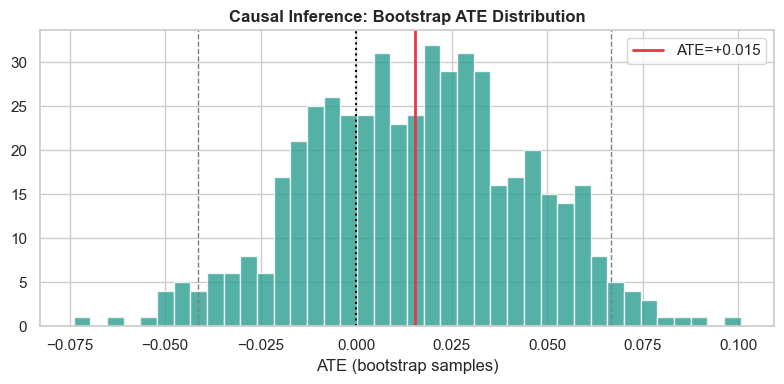

In [13]:
# Cell 13 -- Causal Inference (IPW + Bootstrap CI)
cdf = df[df['is_late']==1].dropna(subset=['distance_km','product_weight_g','price','review_score']).copy()
cdf['T_far'] = (cdf['distance_km'] > cdf['distance_km'].median()).astype(int)
cdf['Y_bad'] = (cdf['review_score'] <= 2).astype(int)
conf = [c for c in ['log_price','product_weight_g','month','freight_ratio','log_seller_orders'] if c in cdf.columns]
ps   = LogisticRegression(max_iter=500).fit(cdf[conf].fillna(0), cdf['T_far'])
cdf['propensity'] = ps.predict_proba(cdf[conf].fillna(0))[:,1]
cdf = cdf[(cdf['propensity']>0.05) & (cdf['propensity']<0.95)]
t_g = cdf[cdf['T_far']==1]; c_g = cdf[cdf['T_far']==0]
ATE = (t_g['Y_bad']/t_g['propensity']).sum()/len(t_g) -       (c_g['Y_bad']/(1-c_g['propensity'])).sum()/len(c_g)
np.random.seed(42)
boot = []
for _ in range(500):
    s  = cdf.sample(len(cdf), replace=True)
    ts = s[s['T_far']==1]; cs = s[s['T_far']==0]
    if len(ts)>0 and len(cs)>0:
        boot.append((ts['Y_bad']/ts['propensity']).sum()/len(ts) -
                    (cs['Y_bad']/(1-cs['propensity'])).sum()/len(cs))
ci = np.percentile(boot, [2.5, 97.5])
print(f'IPW ATE={ATE:+.3f}  95%CI=[{ci[0]:+.3f},{ci[1]:+.3f}]')
print('CAUSAL: yes' if ci[0]>0 else 'Not significant at 95%')
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot, bins=40, color='#2a9d8f', edgecolor='white', alpha=0.8)
ax.axvline(ATE, color='#e63946', lw=2, label=f'ATE={ATE:+.3f}')
ax.axvline(ci[0], color='gray', ls='--', lw=1); ax.axvline(ci[1], color='gray', ls='--', lw=1)
ax.axvline(0, color='black', lw=1.5, ls=':')
ax.set_xlabel('ATE (bootstrap samples)')
ax.set_title('Causal Inference: Bootstrap ATE Distribution', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()


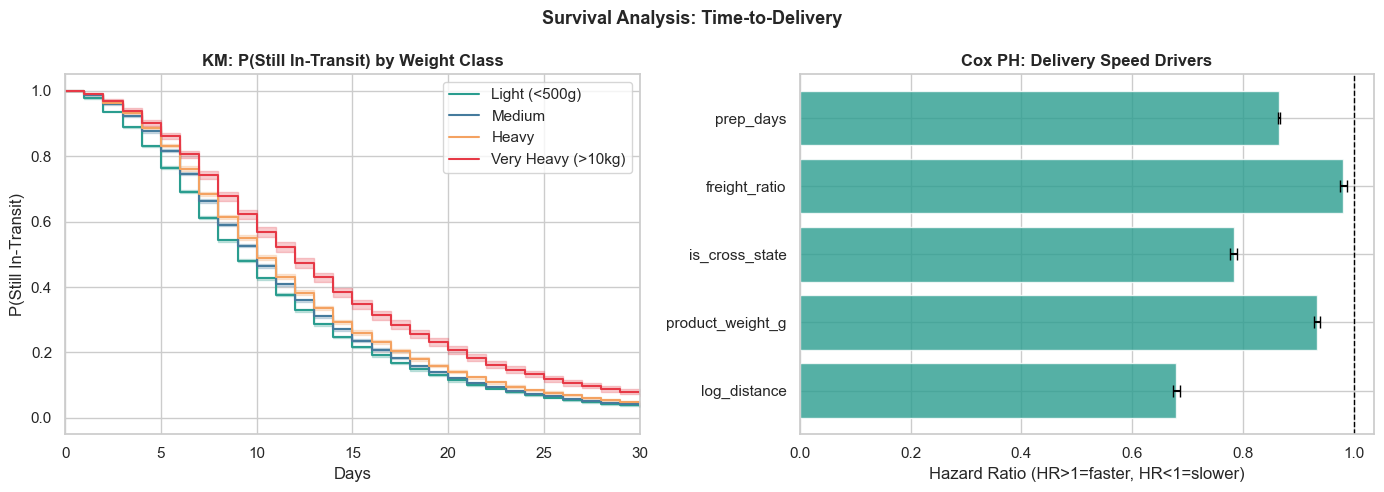

Median delivery: 10 days


In [14]:
# Cell 14 -- Survival Analysis
try:
    from lifelines import KaplanMeierFitter, CoxPHFitter
    sdf = df.copy()
    sdf['delivery_days']  = (sdf['order_delivered_customer_date'] - sdf['order_purchase_timestamp']).dt.days
    sdf['event_observed'] = sdf['order_delivered_customer_date'].notna().astype(int)
    sdf = sdf.dropna(subset=['delivery_days'])
    sdf = sdf[(sdf['delivery_days']>0) & (sdf['delivery_days']<60)]
    sdf['weight_class'] = pd.cut(sdf['product_weight_g'], bins=[0,500,2000,10000,1e9],
                                  labels=['Light (<500g)','Medium','Heavy','Very Heavy (>10kg)'])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    kmf = KaplanMeierFitter()
    pal = ['#2a9d8f','#457b9d','#f4a261','#e63946']
    for cls, col in zip(['Light (<500g)','Medium','Heavy','Very Heavy (>10kg)'], pal):
        mask = sdf['weight_class']==cls
        if mask.sum()>10:
            kmf.fit(sdf.loc[mask,'delivery_days'], event_observed=sdf.loc[mask,'event_observed'], label=cls)
            kmf.plot_survival_function(ax=ax1, color=col)
    ax1.set_title('KM: P(Still In-Transit) by Weight Class', fontweight='bold')
    ax1.set_xlabel('Days'); ax1.set_ylabel('P(Still In-Transit)'); ax1.set_xlim(0, 30)
    cox_feats = [c for c in ['log_distance','product_weight_g','is_cross_state','freight_ratio','prep_days'] if c in sdf.columns]
    cxdf = sdf[cox_feats+['delivery_days','event_observed']].dropna()
    cxn  = cxdf.copy(); cxn[cox_feats] = StandardScaler().fit_transform(cxdf[cox_feats])
    cph  = CoxPHFitter(penalizer=0.1)
    cph.fit(cxn, duration_col='delivery_days', event_col='event_observed')
    hr   = np.exp(cph.params_)
    ci_lo = np.exp(cph.confidence_intervals_['95% lower-bound'])
    ci_hi = np.exp(cph.confidence_intervals_['95% upper-bound'])
    yp = range(len(hr))
    ax2.barh(yp, hr.values, color=['#e63946' if h>1 else '#2a9d8f' for h in hr.values], alpha=0.8)
    ax2.errorbar(hr.values, yp, xerr=[hr.values-ci_lo.values, ci_hi.values-hr.values], fmt='none', color='black', capsize=4)
    ax2.axvline(1, color='black', ls='--', lw=1)
    ax2.set_yticks(yp); ax2.set_yticklabels(hr.index)
    ax2.set_xlabel('Hazard Ratio (HR>1=faster, HR<1=slower)')
    ax2.set_title('Cox PH: Delivery Speed Drivers', fontweight='bold')
    plt.suptitle('Survival Analysis: Time-to-Delivery', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()
    print(f'Median delivery: {KaplanMeierFitter().fit(sdf["delivery_days"],sdf["event_observed"]).median_survival_time_:.0f} days')
except ImportError:
    print('pip install lifelines')


In [15]:
# Cell 15 -- Warehouse Heatmap
al = df[(df['is_late']==1)&(df['review_score']<=2)].dropna(subset=['customer_lat','customer_lng'])
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(al[['customer_lat','customer_lng']].values)
cents = km.cluster_centers_
print('Proposed DC locations (K-Means baseline):')
for i,(lat,lng) in enumerate(cents): print(f'  W{i+1}: {lat:.4f}, {lng:.4f}')
m = folium.Map(location=[-14.235,-51.925], zoom_start=4, tiles='CartoDB dark_matter')
HeatMap([[r.customer_lat,r.customer_lng] for _,r in al.iterrows()],
        radius=12, blur=15, min_opacity=0.4).add_to(m)
for i,(lat,lng) in enumerate(cents):
    folium.Marker([lat,lng], popup=f'DC {i+1}',
                  icon=folium.Icon(color=['red','orange','purple'][i], icon='home')).add_to(m)
display(m)


Proposed DC locations (K-Means baseline):
  W1: -22.0974, -44.8385
  W2: -7.7620, -40.1447
  W3: -26.3314, -51.2782


In [16]:
# Cell 16 -- Final summary + split comparison note
print('=' * 62)
print(f'  SPLIT: {SPLIT_LABEL}')
print('=' * 62)
print(f'  Total orders (test set)     : {len(df_test):>8,}')
print(f'  Confirmed late (test)       : {len(test_late):>8,}')
print(f'  Model A (Delay)  AUC        : {results_a[best_a]["auc"]:>8.4f}  [needs carrier data to improve]')
print(f'  Model B (Anger)  AUC        : {results_b[best_b]["auc"]:>8.4f}  [deployable now]')
print(f'  Model B optimal threshold   : {opt_thresh:>8.2f}')
print(f'  Late orders flagged         : {y_pred_b.sum():>8,} ({y_pred_b.mean():.1%})')
print(f'  Precision                   : {precision:>8.2%}')
print(f'  Recall                      : {recall:>8.2%}')
print(f'  Net saved (base case)       : R$ {saved:>8,.0f}')
print('=' * 62)
print()
print('Compare Model B AUC against claude_temporal.ipynb.')
print('Similar = genuine signal. Random >> Temporal = temporal artefact.')


  SPLIT: Random Stratified 80/20 (stratified on is_late)
  Total orders (test set)     :   19,176
  Confirmed late (test)       :    1,428
  Model A (Delay)  AUC        :   0.7983  [needs carrier data to improve]
  Model B (Anger)  AUC        :   0.8008  [deployable now]
  Model B optimal threshold   :     0.32
  Late orders flagged         :    1,142 (80.0%)
  Precision                   :   66.90%
  Recall                      :   94.79%
  Net saved (base case)       : R$   36,350

Compare Model B AUC against claude_temporal.ipynb.
Similar = genuine signal. Random >> Temporal = temporal artefact.
